# 1 · Model

Notebook 0's model is three modules glued with `nn.Sequential`: the channel count 16 is written in all three, and a new encoder means new glue. Here each part declares its interface, so parts change one at a time and a model can be written as a recipe. Then we add augmentation and compare with notebook 0 in TensorBoard. Data, splits and nodata handling stay the same.

In [24]:
from pathlib import Path

import lightning as L
import torch
from huggingface_hub import snapshot_download
from torch import nn
from torch.utils.data import DataLoader, Dataset

import geosave as gs

# One seed for the whole notebook, so the model's first weights and the shuffled
# batches repeat from run to run.
L.seed_everything(0)

root = Path(
    snapshot_download(
        "fatmur/dynamicworld-300", repo_type="dataset", local_dir="data/dynamic_world"
    )
)


class DynamicWorld(Dataset):
    def __init__(self, images, labels=None):
        self.images = images
        self.labels = labels if labels else None

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        image = gs.open_raster(self.images[index])
        image = image.gs.mask_and_scale().gs.to_tensor(dtype="float32")
        image = image.nan_to_num()  # (4, H, W)
        if self.labels is None:
            return image

        label = gs.open_raster(self.labels[index])["label"]
        label = label.gs.mask_and_scale().gs.to_tensor(dtype="float32")
        label = label.nan_to_num(255).long()  # (H, W)
        return image, label


train_images = sorted((root / "train/images").glob("*.tif"))
train_labels = sorted((root / "train/labels").glob("*.tif"))
val_images = sorted((root / "val/images").glob("*.tif"))
val_labels = sorted((root / "val/labels").glob("*.tif"))

train = DynamicWorld(train_images, train_labels)
val = DynamicWorld(val_images, val_labels)
train_loader = DataLoader(train, batch_size=8, shuffle=True)
val_loader = DataLoader(val, batch_size=8)

Seed set to 0
2026-10-16 16:00:18,749 - INFO - HTTP Request: GET https://huggingface.co/api/datasets/fatmur/dynamicworld-300/revision/main "HTTP/1.1 200 OK"


Fetching 603 files:   0%|          | 0/603 [00:00<?, ?it/s]

## The same three parts

Ordinary PyTorch modules, plus declarations GeoSave uses to connect and build them.

In [25]:
from geosave.model import ModelChain, Published, build_model, chain_step
from geosave.model.registry import register_model


@register_model("encoder", "tiny")
class Encoder(nn.Module):
    channels: Published[int]

    def __init__(self, channels: int = 16):
        super().__init__()
        self.channels = channels
        self.net = nn.Sequential(
            nn.Conv2d(4, channels, 3, stride=2, padding=1), nn.ReLU()
        )

    @chain_step()
    def forward(self, image: torch.Tensor) -> torch.Tensor:
        features = self.net(image)  # (B, 4, H, W) -> (B, channels, H/2, W/2)
        return features


@register_model("decoder", "upsample")
class Decoder(nn.Module):
    feature_channels: Published[int]

    def __init__(self, channels: int):
        super().__init__()
        self.feature_channels = channels
        self.net = nn.Sequential(
            nn.Upsample(scale_factor=2),
            nn.Conv2d(channels, channels, 3, padding=1),
            nn.ReLU(),
        )

    @chain_step()
    def forward(self, features: torch.Tensor) -> torch.Tensor:
        feature_map = self.net(
            features
        )  # (B, channels, H/2, W/2) -> (B, channels, H, W)
        return feature_map


@register_model("head", "pixel")
class Head(nn.Module):
    def __init__(self, channels: int):
        super().__init__()
        self.net = nn.Conv2d(channels, 10, 1)

    @chain_step(head=True)
    def forward(self, feature_map: torch.Tensor) -> torch.Tensor:
        return self.net(feature_map)  # (B, channels, H, W) -> (B, 10, H, W)

## Connect parts by what they read and return

`chain_step` declares the named values a part reads and produces. `ModelChain` wires them into a graph: the encoder makes `features`, the decoder `feature_map`, the head the scores. Displaying the model shows that flow.

In [26]:
model = ModelChain(
    encoder=Encoder(),
    decoder=Decoder(channels=16),
    head=Head(channels=16),
)
model

```mermaid
flowchart LR
    input_image(["image: Tensor"])
    encoder["encoder: Encoder.forward"]
    decoder["decoder: Decoder.forward"]
    head["head: Head.forward"]
    result_head(["Tensor"])
    input_image -->|"image"| encoder
    encoder -->|"features: Tensor"| decoder
    decoder -->|"feature_map: Tensor"| head
    head --> result_head
```

## Swap the decoder

This decoder resizes to the image's size, so it reads `features` and `image`:

In [27]:
class ResizeDecoder(nn.Module):
    @chain_step()
    def forward(self, features: torch.Tensor, image: torch.Tensor) -> torch.Tensor:
        feature_map = nn.functional.interpolate(
            features, size=image.shape[-2:], mode="bilinear", align_corners=False
        )
        return feature_map


model = ModelChain(
    encoder=Encoder(),
    decoder=ResizeDecoder(),
    head=Head(channels=16),
)
model

```mermaid
flowchart LR
    input_image(["image: Tensor"])
    encoder["encoder: Encoder.forward"]
    decoder["decoder: ResizeDecoder.forward"]
    head["head: Head.forward"]
    result_head(["Tensor"])
    input_image -->|"image"| encoder
    encoder -->|"features: Tensor"| decoder
    input_image -->|"image"| decoder
    decoder -->|"feature_map: Tensor"| head
    head --> result_head
```

The encoder and head are unchanged: each step receives only the values it asks for, and gradients still flow back to the encoder.

## Change the width in one place

`channels: Published[int]` on the encoder passes its width to parts built after it. `build_model` constructs the parts in order, so one change widens all three:

In [28]:
model = build_model({"encoder": Encoder(channels=32), "decoder": Decoder, "head": Head})
model

```mermaid
flowchart LR
    input_image(["image: Tensor"])
    encoder["encoder: Encoder.forward"]
    decoder["decoder: Decoder.forward"]
    head["head: Head.forward"]
    result_head(["Tensor"])
    input_image -->|"image"| encoder
    encoder -->|"features: Tensor"| decoder
    decoder -->|"feature_map: Tensor"| head
    head --> result_head
```

## Write the model as a recipe

`@register_model` names each class within its stage. Selected by name, the model is plain data, the form a YAML or JSON config holds:

In [29]:
model = build_model(
    {
        "encoder": {"name": "tiny", "init_args": {"channels": 16}},
        "decoder": {"name": "upsample"},
        "head": {"name": "pixel"},
    }
)
model

```mermaid
flowchart LR
    input_image(["image: Tensor"])
    encoder["encoder: Encoder.forward"]
    decoder["decoder: Decoder.forward"]
    head["head: Head.forward"]
    result_head(["Tensor"])
    input_image -->|"image"| encoder
    encoder -->|"features: Tensor"| decoder
    decoder -->|"feature_map: Tensor"| head
    head --> result_head
```

## Parts GeoSave provides

Pretrained encoders, decoders and heads are registered the same way. `list_models` shows how each is called, what it publishes and what it needs:

In [30]:
from geosave.model import list_models

list_models()

forward  \
stage   name                                                                     
encoder tiny                                                    forward(image)   
        clay                    forward_pyramid(image, time=None, latlon=None)   
        dinov3                                          forward_pyramid(image)   
        prithvi                                         forward_pyramid(image)   
        prithvi_tl           forward_pyramid(image, temporal_coords, locati...   
        small_cnn                                       forward_pyramid(image)   
decoder upsample                                             forward(features)   
        dpt                                    forward(pyramid, prefix_tokens)   
        unet                                                  forward(pyramid)   
head    pixel                                             forward(feature_map)   
        classification                                 forward_logits(pyramid)   
        regression                                 forward_logits(feature_map)   
        segmentation                               forward_logits(feature_map)   
model   ibm_granite_biomass                                     forward(image)   

                                                                 publishes  \
stage   name                                                                 
encoder tiny                                                      channels   
        clay                 pyramid_channels, pyramid_strides, input_size   
        dinov3               pyramid_channels, pyramid_strides, input_size   
        prithvi              pyramid_channels, pyramid_strides, input_size   
        prithvi_tl           pyramid_channels, pyramid_strides, input_size   
        small_cnn            pyramid_channels, pyramid_strides, input_size   
decoder upsample                                          feature_channels   
        dpt                                               feature_channels   
        unet                                              feature_channels   
head    pixel                                                                
        classification                                                       
        regression                                                           
        segmentation                                                         
model   ibm_granite_biomass                                                  

                                            requires  
stage   name                                          
encoder tiny                                          
        clay                 in_channels, waves, gsd  
        dinov3                                        
        prithvi                                       
        prithvi_tl                                    
        small_cnn                                     
decoder upsample                                      
        dpt                                           
        unet                                          
head    pixel                                         
        classification                   num_classes  
        regression                         variables  
        segmentation                     num_classes  
model   ibm_granite_biomass

Naming a part lists what can run before and after it:

In [31]:
list_models("upsample")

,before,after
encoder,tiny,
head,,"pixel, regression, segmentation"


GeoSave's `segmentation` head replaces ours: same 1x1 layer, but the class count comes from the label file. We keep width 16, so the flips below are the only change from notebook 0.

In [32]:
label = gs.open_raster(train_labels[0])["label"]
# 255 marks unlabelled pixels, not a class
num_classes = sum(
    code != 255 for code in label.gs.legend.classes
)  # number of actual classes

model = build_model(
    {
        "encoder": {"name": "tiny", "init_args": {"channels": 16}},
        "decoder": {"name": "upsample"},
        "head": {"name": "segmentation", "init_args": {"num_classes": num_classes}},
    }
)
model

```mermaid
flowchart LR
    input_image(["image: Tensor"])
    encoder["encoder: Encoder.forward"]
    decoder["decoder: Decoder.forward"]
    head["head: SegmentationHead.forward_logits"]
    result_head(["Tensor"])
    input_image -->|"image"| encoder
    encoder -->|"features: Tensor"| decoder
    decoder -->|"feature_map: Tensor"| head
    head --> result_head
```

## Augmentation

[Kornia](https://kornia.readthedocs.io) augments whole batches. `AugmentationSequential` applies the same flip to image and labels; `data_keys` says which is which.

In [33]:
import kornia.augmentation as K
import lightning as L
from torchmetrics import MetricCollection
from torchmetrics.classification import MulticlassAccuracy, MulticlassJaccardIndex


class Segmenter(L.LightningModule):
    def __init__(self, model, num_classes):
        super().__init__()
        self.model = model
        self.augment = K.AugmentationSequential(
            K.RandomHorizontalFlip(),
            K.RandomVerticalFlip(),
            data_keys=["image", "mask"],
            keepdim=True,
        )
        self.val_metrics = MetricCollection(
            {
                "miou": MulticlassJaccardIndex(
                    num_classes=num_classes, ignore_index=255
                ),
                "accuracy": MulticlassAccuracy(
                    num_classes=num_classes, ignore_index=255, average="micro"
                ),
            },
            prefix="val_",
        )
        self.criterion = nn.CrossEntropyLoss(ignore_index=255)

    def forward(self, image):
        return self.model(image=image)

    def training_step(self, batch, batch_index):
        image, label = self.augment(*batch)  # (B, C, H, W), (B, H, W)
        logits = self(image)  # (B, classes, H, W)
        loss = self.criterion(logits, label)
        self.log("train_loss", loss)
        return loss

    def validation_step(self, batch, batch_index):
        image, label = batch  # (B, C, H, W), (B, H, W)
        logits = self(image)  # (B, classes, H, W)
        loss = self.criterion(logits, label)
        self.log("val_loss", loss)
        self.val_metrics(logits, label)
        self.log_dict(self.val_metrics)

    def configure_optimizers(self):
        return torch.optim.AdamW(self.parameters(), lr=1e-2)


module = Segmenter(model, num_classes)

In [34]:
import warnings

from lightning.pytorch.callbacks import ModelCheckpoint
from lightning.pytorch.loggers import TensorBoardLogger

# The tiles are small and few; Lightning's hint to add loader workers is noise here.
warnings.filterwarnings("ignore", ".*does not have many workers.*")

# Each notebook logs to a folder of its own; version 0 is its one run.
logger = TensorBoardLogger("lightning_logs", name="01_model", version=0)
# The last epoch is kept, so running this cell again resumes the finished run.
checkpoint = ModelCheckpoint(save_last=True)

trainer = L.Trainer(
    max_epochs=6,
    limit_train_batches=6,
    limit_val_batches=2,
    log_every_n_steps=1,
    logger=logger,
    callbacks=[checkpoint],
)
trainer.fit(module, train_loader, val_loader, ckpt_path="last")

GPU available: False, used: False
TPU available: False, using: 0 TPU cores
💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
/home/uwu/Projects/geosave/.venv/lib/python3.14/site-packages/lightning/pytorch/callbacks/model_checkpoint.py:881: Checkpoint directory lightning_logs/01_model/version_0/checkpoints exists and is not empty.
Restoring states from the checkpoint path at /home/uwu/Projects/geosave/examples/lightning_logs/01_model/version_0/checkpoints/last.ckpt


┏━━━┳━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name        ┃ Type                   ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ model       │ ModelChain             │  3.1 K │ train │     0 │
│ 1 │ augment     │ AugmentationSequential │      0 │ train │     0 │
│ 2 │ val_metrics │ MetricCollection       │      0 │ train │     0 │
│ 3 │ criterion   │ CrossEntropyLoss       │      0 │ train │     0 │
└───┴─────────────┴────────────────────────┴────────┴───────┴───────┘

Trainable params: 3.1 K                                                                                            
Non-trainable params: 0                                                                                            
Total params: 3.1 K                                                                                                
Total estimated model params size (MB): 0                                                                          
Modules in train mode: 20                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Restored all states from the checkpoint at /home/uwu/Projects/geosave/examples/lightning_logs/01_model/version_0/checkpoints/last.ckpt


Output()

/home/uwu/Projects/geosave/.venv/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: 
`isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` 
instead.

/home/uwu/Projects/geosave/.venv/lib/python3.14/site-packages/lightning/pytorch/utilities/_pytree.py:21: 
`isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` 
instead.

`Trainer.fit` stopped: `max_epochs=6` reached.


## Compare the runs

TensorBoard draws `00_basics` and `01_model` on the same axes. Six short epochs are noisy, so read the gap loosely.

In [35]:
%load_ext tensorboard
%tensorboard --logdir lightning_logs

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


Reusing TensorBoard on port 6006 (pid 57992), started 6:34:02 ago. (Use '!kill 57992' to kill it.)

:Layout
   .RGB.I      :RGB   [x,y]   (R,G,B)
   .Overlay.I  :Overlay
      .RGB.I                     :RGB   [x,y]   (R,G,B)
      .Points.Water              :Points   [x,y]
      .Points.Trees              :Points   [x,y]
      .Points.Grass              :Points   [x,y]
      .Points.Flooded_vegetation :Points   [x,y]
      .Points.Crops              :Points   [x,y]
      .Points.Scrub              :Points   [x,y]
      .Points.Built_area         :Points   [x,y]
      .Points.Bare_ground        :Points   [x,y]
      .Points.Snow_ice           :Points   [x,y]
      .Points.Cloud              :Points   [x,y]
      .Points.Unlabelled         :Points   [x,y]
   .Overlay.II :Overlay
      .RGB.I                     :RGB   [x,y]   (R,G,B)
      .Points.Water              :Points   [x,y]
      .Points.Trees              :Points   [x,y]
      .Points.Grass              :Points   [x,y]
      .Points.Flooded_vegetation :Points   [x,y]
      .Points.Crops              :Points   [x,y]
      .Points.Scrub              :Points   [x,y]
      .Points.Built_area         :Points   [x,y]
      .Points.Bare_ground        :Points   [x,y]
      .Points.Snow_ice           :Points   [x,y]
      .Points.Cloud              :Points   [x,y]
      .Points.Unlabelled         :Points   [x,y]
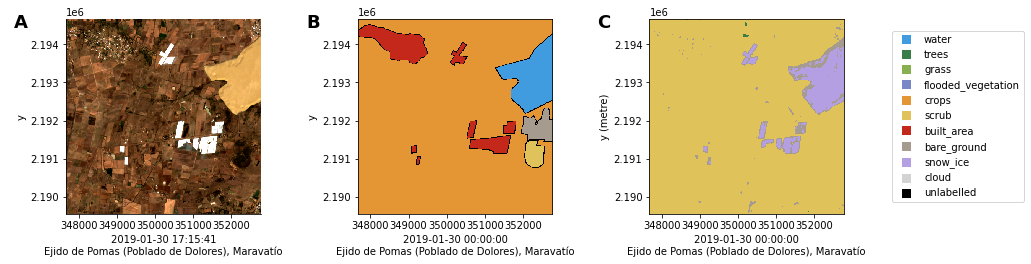

In [36]:
images, _ = next(iter(val_loader))  # (B, C, H, W)
module.eval()
with torch.no_grad():
    logits = module(images.to(module.device)).cpu()  # (B, classes, H, W)
    # Dim 0 is the batch, so classes are dim 1; [0] keeps the first tile.
    prediction = logits.argmax(dim=1)[0]  # (H, W)

image = gs.open_raster(val_images[0])
label = gs.open_raster(val_labels[0])["label"]
pred = prediction.numpy().astype("uint8")
predicted = gs.raster(
    variables={
        "label": (("y", "x"), pred)
    },  # y x is the dims assigned to the numpy array
    reference=label,
    nodata=255,
)

image.gs.plot() + label.gs.plot() + predicted.gs.plot()

## What happened

We resized and swapped parts, wrote the model as a recipe, replaced our head with a built-in one, and trained with flips. Next, we build a dataset like this one ourselves.

| Next | Question |
| --- | --- |
| 2 · Build a dataset | How do I build a dataset like this one for my own labels, places and dates? |

## Your turn

Easy to advanced; solutions are folded under each exercise.

### 1 · What fits together? (easy)

`list_models` names what can run before and after a part. Which GeoSave encoders can feed the built-in `unet` decoder, and which heads can follow it?

<details><summary>Solution</summary>

```python
list_models("unet")
```
</details>

In [37]:
# Your code here

### 2 · A wider model (easy)

Build the recipe with `channels` set to 32, train it under its own logger name, as `01_wide`, and compare it with this run in TensorBoard. How many parts of the recipe did you change?

<details><summary>Hint</summary>

Only the encoder's `init_args` change; the decoder and head take the published width. Give the new model a fresh `Segmenter(model, num_classes)`, and the `Trainer` a new `TensorBoardLogger`.
</details>

In [38]:
# Your code here

### 3 · Another augmentation (medium)

Satellite pictures have no "up", so a quarter turn is as fair as a flip. Add `K.RandomRotation90(times=(0, 3))` to the `Segmenter`'s augmentation, train, and compare. First plot one augmented batch to check that the labels turn with their pictures.

<details><summary>Hint</summary>

`module.augment(*next(iter(train_loader)))` returns one augmented batch. `gs.raster({"label": (("y", "x"), labels[0].numpy().astype("uint8"))}, label)` puts a label tensor back on a tile's grid for plotting, as notebook 0 did with its prediction.
</details>

In [39]:
# Your code here

### 4 · Your own decoder (advanced)

Write a decoder with two convolutions instead of one, register it as `"deep"`, and select it in the recipe by name. The head must still follow its width without being told.

<details><summary>Hint</summary>

Copy `Decoder`: its `feature_channels: Published[int]` is what lets the head find its width.
</details>

<details><summary>Solution</summary>

```python
@register_model("decoder", "deep")
class DeepDecoder(nn.Module):
    feature_channels: Published[int]

    def __init__(self, channels: int):
        super().__init__()
        self.feature_channels = channels
        self.net = nn.Sequential(
            nn.Upsample(scale_factor=2),
            nn.Conv2d(channels, channels, 3, padding=1),
            nn.ReLU(),
            nn.Conv2d(channels, channels, 3, padding=1),
            nn.ReLU(),
        )

    @chain_step()
    def forward(self, features: torch.Tensor) -> torch.Tensor:
        feature_map = self.net(features)
        return feature_map


model = build_model({
    "encoder": {"name": "tiny", "init_args": {"channels": 16}},
    "decoder": {"name": "deep"},
    "head": {"name": "segmentation", "init_args": {"num_classes": num_classes}},
})
```
</details>

In [40]:
# Your code here